# Plik z roznymi pomocniczymi wizualizacjami


Załadowanie bibliotek

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma, lognorm, pareto

## Rozklad gamma vs lognormal vs pareto

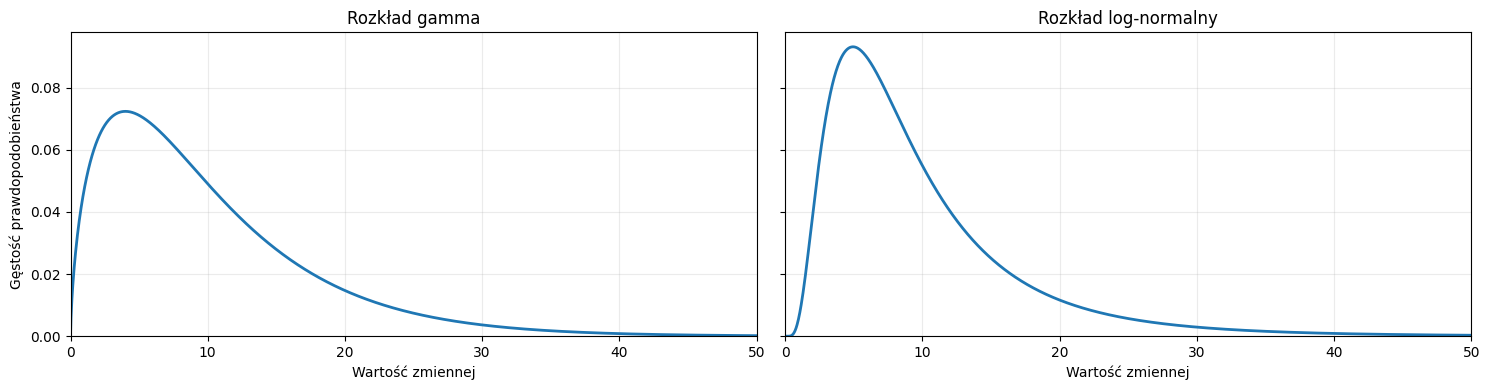

In [30]:

# Wspólne momenty
mean = 10
variance = 60

# Gamma
k = mean**2 / variance
theta = variance / mean

# Log-normal
sigma2 = np.log(1 + variance / mean**2)
sigma = np.sqrt(sigma2)
mu = np.log(mean) - sigma2 / 2

# Pareto
alpha = 1 + np.sqrt(1 + mean**2 / variance)
xm = mean * (alpha - 1) / alpha

# Zakres osi X
x = np.linspace(0.001, 50, 1500)

# Gęstości
distributions = [
    (gamma.pdf(x, a=k, scale=theta), 'Rozkład gamma'),
    (lognorm.pdf(x, s=sigma, scale=np.exp(mu)), 'Rozkład log-normalny')
    # (pareto.pdf(x, b=alpha, scale=xm), 'Rozkład Pareto')
]

# Wspólna skala Y
y_max = max(np.max(pdf) for pdf, _ in distributions)

# Wykresy
fig, axes = plt.subplots(1, 2, figsize=(15, 4),
                         sharex=True, sharey=True)

for ax, (pdf, label) in zip(axes, distributions):
    ax.plot(x, pdf, linewidth=2)
    ax.set_title(label)
    ax.set_xlabel('Wartość zmiennej')
    ax.set_xlim(0, 50)
    ax.set_ylim(0, y_max * 1.05)
    ax.grid(alpha=0.25)

axes[0].set_ylabel('Gęstość prawdopodobieństwa')

plt.tight_layout()
plt.show()